# Online Machine Learning with CapyMOA — Steps 7–10

This notebook presents executed results and provides an entry point for reproduction. The full test-then-train loops are implemented in [capy_lab/experiments.py](../capy_lab/experiments.py); formal runs are reproduced through [REPRODUCIBILITY.md](../REPRODUCIBILITY.md).

By default, the notebook reads saved evidence rather than retraining the formal models. One clearly labeled 100-observation example trains an illustrative learner only; its scores never enter the formal CSV files or report. Set `RERUN_EXPERIMENTS=True` only in a separate working copy when formal runner execution is intended.

## Source navigation

- [Full evaluation implementation](../capy_lab/experiments.py)
- [Model constructors and settings](../capy_lab/models.py)
- [Formal run entry point](../scripts/run_capy.py)
- [Installation and two-level reproduction guide](../REPRODUCIBILITY.md)
- [Formal measured results](../results/capymoa/)

## Step 7 — Installation and Java configuration

Select **Python 3.11 (lab4 CapyMOA)**. Before importing CapyMOA, configure Java 17, the 4 GiB maximum heap, one active processor and the verified seeded overlay. Part 1 retains its `.venv`; this part uses `.venv-capy` and `requirements-capy.txt`.

In [1]:
from pathlib import Path
import os, sys, json, subprocess, importlib.metadata
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'config/capymoa.json').exists())
os.chdir(PROJECT);sys.path.insert(0,str(PROJECT))
from capy_lab.runtime import configure
config=configure()
import capymoa
import pandas as pd
from IPython.display import display, Markdown, Image
print('Project:', PROJECT.name)
print('Python:', sys.version.split()[0])
# Retain runtime/version evidence without printing machine-specific paths.
import io
from contextlib import redirect_stdout
runtime_description = io.StringIO()
with redirect_stdout(runtime_description):
    capymoa.about()
for runtime_line in runtime_description.getvalue().splitlines():
    runtime_line = runtime_line.strip()
    if runtime_line.startswith(('CapyMOA ', 'CAPYMOA_JVM_ARGS:', 'MOA version:', 'JAVA version:')):
        print(runtime_line)
print('Seeded AutoML patch:',json.loads((PROJECT/'vendor/automl-seeded.json').read_text())['overlay_sha256'])
for name in ['river','numpy','pandas','scikit-learn','jupyterlab']:
    print(name,importlib.metadata.version(name))
pd.set_option('display.max_rows',100)
pd.set_option('display.max_columns',20)
pd.set_option('display.float_format',lambda x:f'{x:.4f}')
OUT=PROJECT/'results/capymoa';FIG=OUT/'figures'

# A virtual-environment folder name is advisory; the interpreter can live elsewhere.
if Path(sys.prefix).resolve() != (PROJECT / '.venv-capy').resolve():
    print('NOTE: custom kernel prefix detected. Folder names are not required to match.')
expected_core_versions = {'capymoa': '0.15.1', 'river': '0.26.1'}
observed_core_versions = {p: importlib.metadata.version(p) for p in expected_core_versions}
print('Expected core versions:', expected_core_versions)
print('Observed core versions:', observed_core_versions)
if observed_core_versions != expected_core_versions:
    print('NOTE: versions differ from the measured environment. Use the separate dependency locks before formal training; runtime identities control cache reuse.')


Project: submit_formal
Python: 3.11.16


CapyMOA 0.15.1
CAPYMOA_JVM_ARGS:     ['-Xmx4g', '-Xss8m', '-XX:ActiveProcessorCount=1']
MOA version:          e7d7c3d533a4800bf2581f820d2c1e9310d70ff40b52fc1a742793eceb89a660
JAVA version:         17.0.20.1
Seeded AutoML patch: 0dcf5096735e307b8a13c8148168dfa09faee7b355197042e031e10068c6b259
river 0.26.1
numpy 2.4.6
pandas 2.3.3
scikit-learn 1.9.1
jupyterlab 4.6.6
NOTE: custom kernel prefix detected. Folder names are not required to match.
Expected core versions: {'capymoa': '0.15.1', 'river': '0.26.1'}
Observed core versions: {'capymoa': '0.15.1', 'river': '0.26.1'}


## Run control and scope

The formal study contains 96 classification runs, 27 clustering runs and 24 AutoML runs. Each job runs sequentially in a fresh process. The three model seeds share the same cached stream; they are not independent dataset realizations. Exploratory trials are excluded.

In [2]:
# Refresh or reuse compatible formal results; --resume does not force retraining.
RERUN_EXPERIMENTS=False
if RERUN_EXPERIMENTS:
    subprocess.run([sys.executable,'scripts/run_capy.py','all','--resume'],check=True)
    subprocess.run([sys.executable,'scripts/run_capy.py','analyze'],check=True)
print(json.dumps(config,indent=2))
data_manifest=json.loads((PROJECT/'data/manifest.json').read_text())
display(pd.DataFrame(data_manifest['datasets'])[['dataset','task','n_samples','original_n_samples']])


{
  "seeds": [
    42,
    43,
    44
  ],
  "classification_datasets": [
    "Elec2",
    "Phishing",
    "ImageSegments",
    "SEARecurring"
  ],
  "families": [
    "HoeffdingTree",
    "AdaptiveRandomForest",
    "LinearLogistic",
    "GaussianNB"
  ],
  "checkpoint_every": 200,
  "rolling_window": 500,
  "forest_trees": 5,
  "tree_grace_period": 100,
  "tree_memory_mib": 64,
  "tree_max_depth": null,
  "jvm_args": "-Xmx4g -Xss8m -XX:ActiveProcessorCount=1",
  "cluster_datasets": [
    "ImageSegments",
    "Phishing",
    "MovingGaussians"
  ],
  "cluster_models": [
    "CluStream",
    "ClusTree",
    "DenStream"
  ],
  "cluster_calibration": 200,
  "cluster_macro_k": 3,
  "cluster_refresh": 200,
  "cluster_eval_every": 500,
  "cluster_synthetic_n": 6000,
  "cluster_synthetic_seed": 2026,
  "automl_datasets": [
    "Elec2",
    "SEARecurring"
  ],
  "automl_models": [
    "FixedHT",
    "Bandit",
    "SuccessiveHalving",
    "AutoClass"
  ],
  "worker_timeout_s": 300
}


,dataset,task,n_samples,original_n_samples
0,TrumpApproval,regression,1001,1001
1,ChickWeights,regression,578,578
2,Bikes,regression,10000,182470
3,FriedmanDrift,regression,10000,10000
4,Elec2,classification,10000,45312
5,Phishing,classification,1250,1250
6,ImageSegments,classification,2310,2310
7,SEARecurring,classification,10000,10000


## Step 8 — Classification on common inputs

Use Elec2, Phishing, ImageSegments and SEARecurring. Both libraries receive the same fixed-dimensional vectors, with absent one-hot entries filled by zero. Shared settings include grace=100, memory parameter=64 MiB, adaptive-NB leaves, five forest trees, lambda=6, integer floor(sqrt(d)) features and ADWIN deltas 0.002/0.01. Both omit a depth cap because MOA has no equivalent option. Part 1 instead uses sparse inputs and depth 12.

**LinearLogistic is an approximate correspondence**: River Adam and CapyMOA inverse-scaling sklearn SGD are different optimizers. Linear models share causal online scaling. Prediction objects contain a fixed class-slot zero; true labels are used after prediction for scoring and training.

Item latency includes adapters, preprocessing and learning, but excludes cache reading, initial JVM startup and metric computation. Interface costs and first-call JIT effects remain relevant.

,dataset,model,library,accuracy,macro_f1,kappa,mean_latency_us,p95_latency_us,total_runtime_s,sampled_peak_process_rss_mib
0,Elec2,HoeffdingTree,River,0.8394,0.8344,0.6694,80.2897,93.9799,0.8623,140.9909
1,Elec2,HoeffdingTree,CapyMOA,0.8450,0.8402,0.6810,82.1077,112.0671,0.8896,304.7604
2,Elec2,AdaptiveRandomForest,CapyMOA,0.8640,0.8610,0.7221,198.3995,446.6446,2.0658,428.5117
3,Elec2,AdaptiveRandomForest,River,0.8465,0.8421,0.6847,418.6277,672.5904,4.2634,146.7682
4,Elec2,LinearLogistic,River,0.8575,0.8542,0.7085,62.2236,66.9796,0.6815,139.8451
5,Elec2,LinearLogistic,CapyMOA,0.7371,0.7009,0.4315,933.2891,1106.7538,9.4238,270.3451
6,Elec2,GaussianNB,CapyMOA,0.7720,0.7588,0.5227,57.5128,78.9859,0.6366,271.0169
7,Elec2,GaussianNB,River,0.7719,0.7588,0.5226,157.4374,201.1226,1.6449,140.7227
8,Phishing,HoeffdingTree,River,0.8752,0.8734,0.7468,67.4644,72.8891,0.0915,135.4349
9,Phishing,HoeffdingTree,CapyMOA,0.8816,0.8803,0.7608,105.8447,104.1230,0.1409,270.7083


,dataset,model,accuracy_difference_pp,capy_to_river_latency_ratio
0,Elec2,HoeffdingTree,0.5600,1.0227
1,Elec2,AdaptiveRandomForest,1.7467,0.4742
2,Elec2,LinearLogistic,-12.0400,15.0026
3,Elec2,GaussianNB,0.0100,0.3657
4,Phishing,HoeffdingTree,0.6400,1.5690
5,Phishing,AdaptiveRandomForest,0.8800,0.6138
6,Phishing,LinearLogistic,-3.1200,18.1929
7,Phishing,GaussianNB,0.0000,0.4493
8,ImageSegments,HoeffdingTree,0.0433,0.3030
9,ImageSegments,AdaptiveRandomForest,-6.5657,0.3169


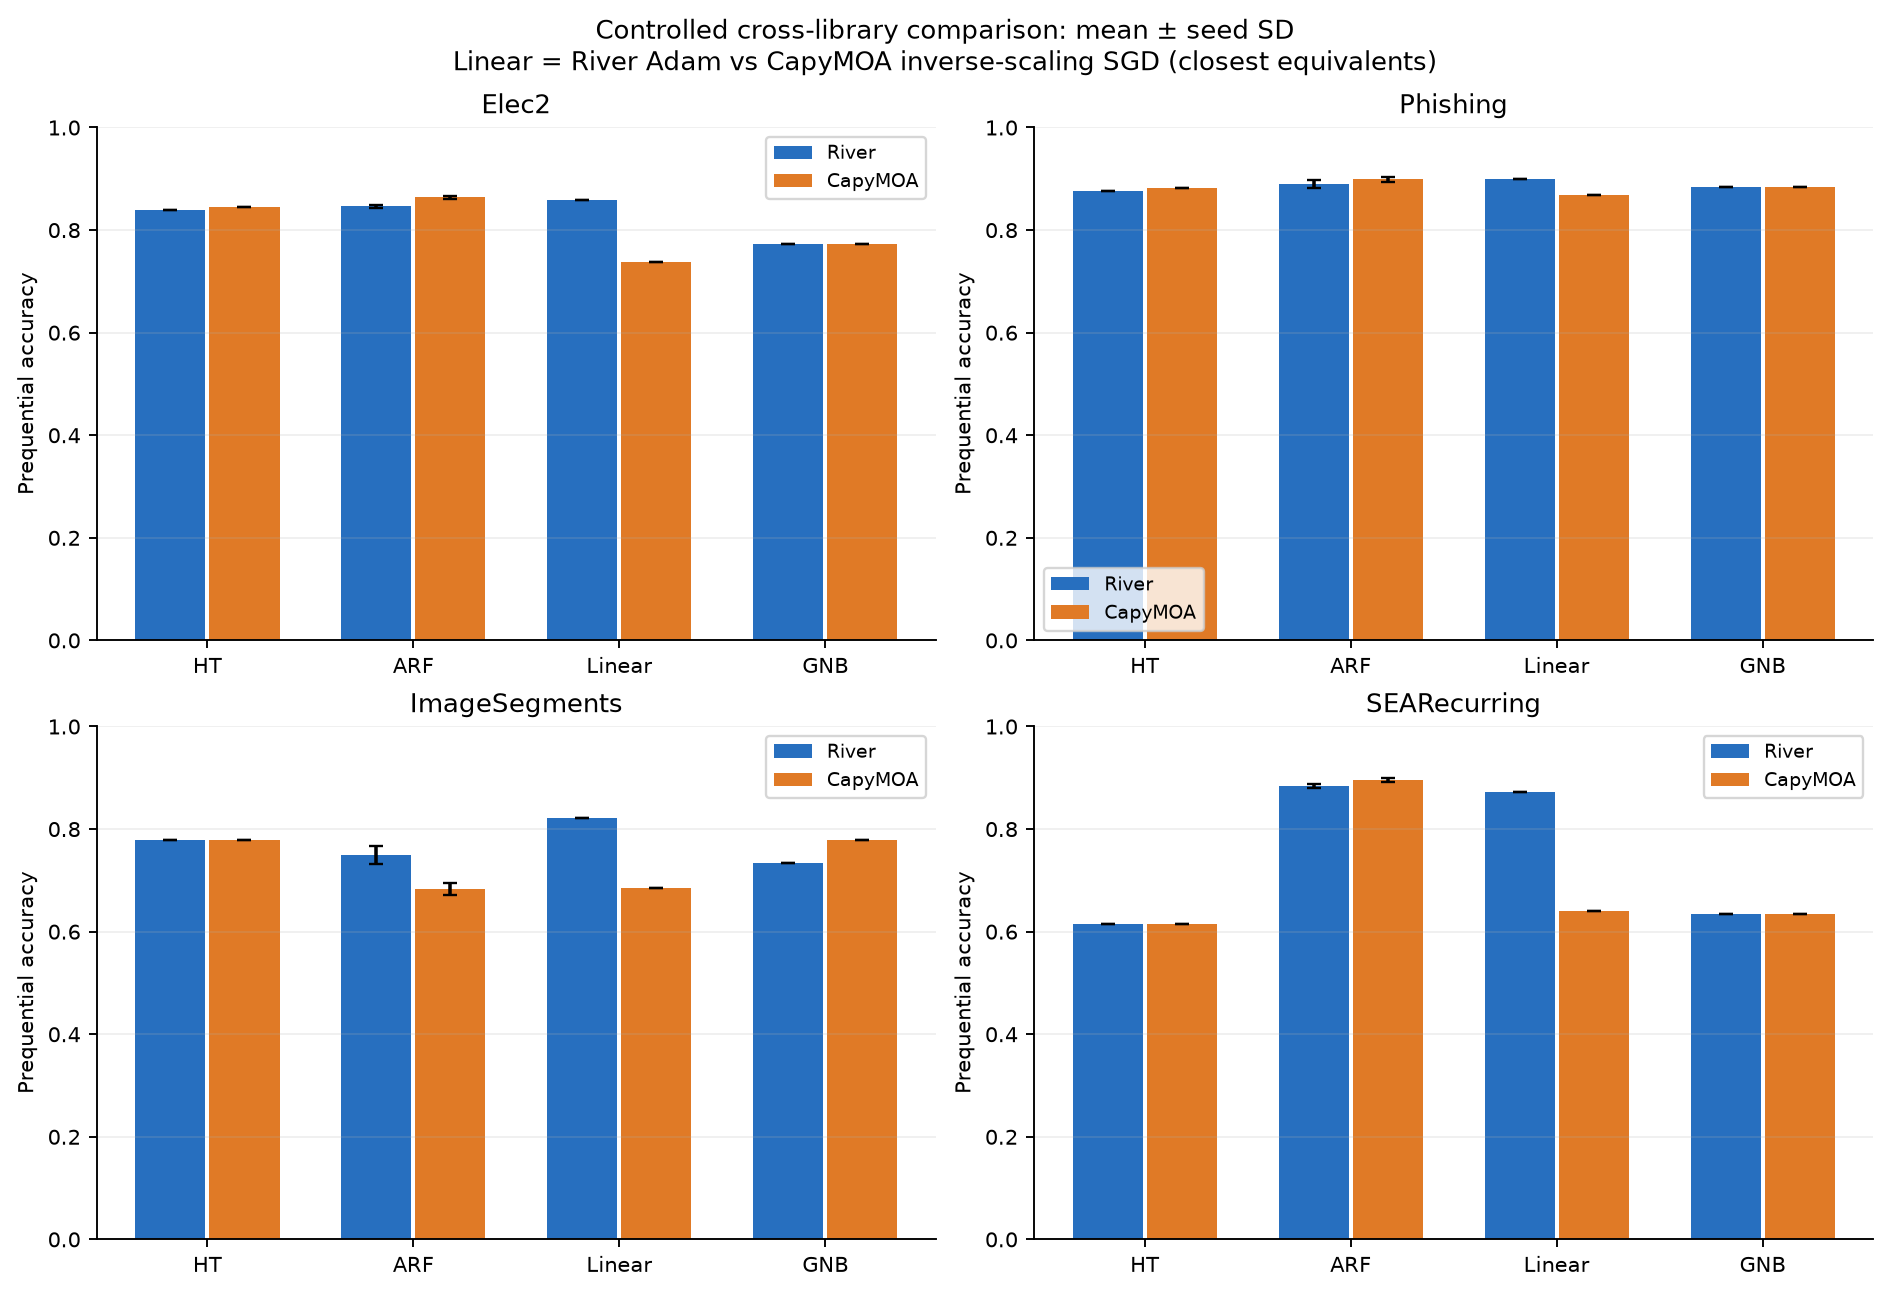

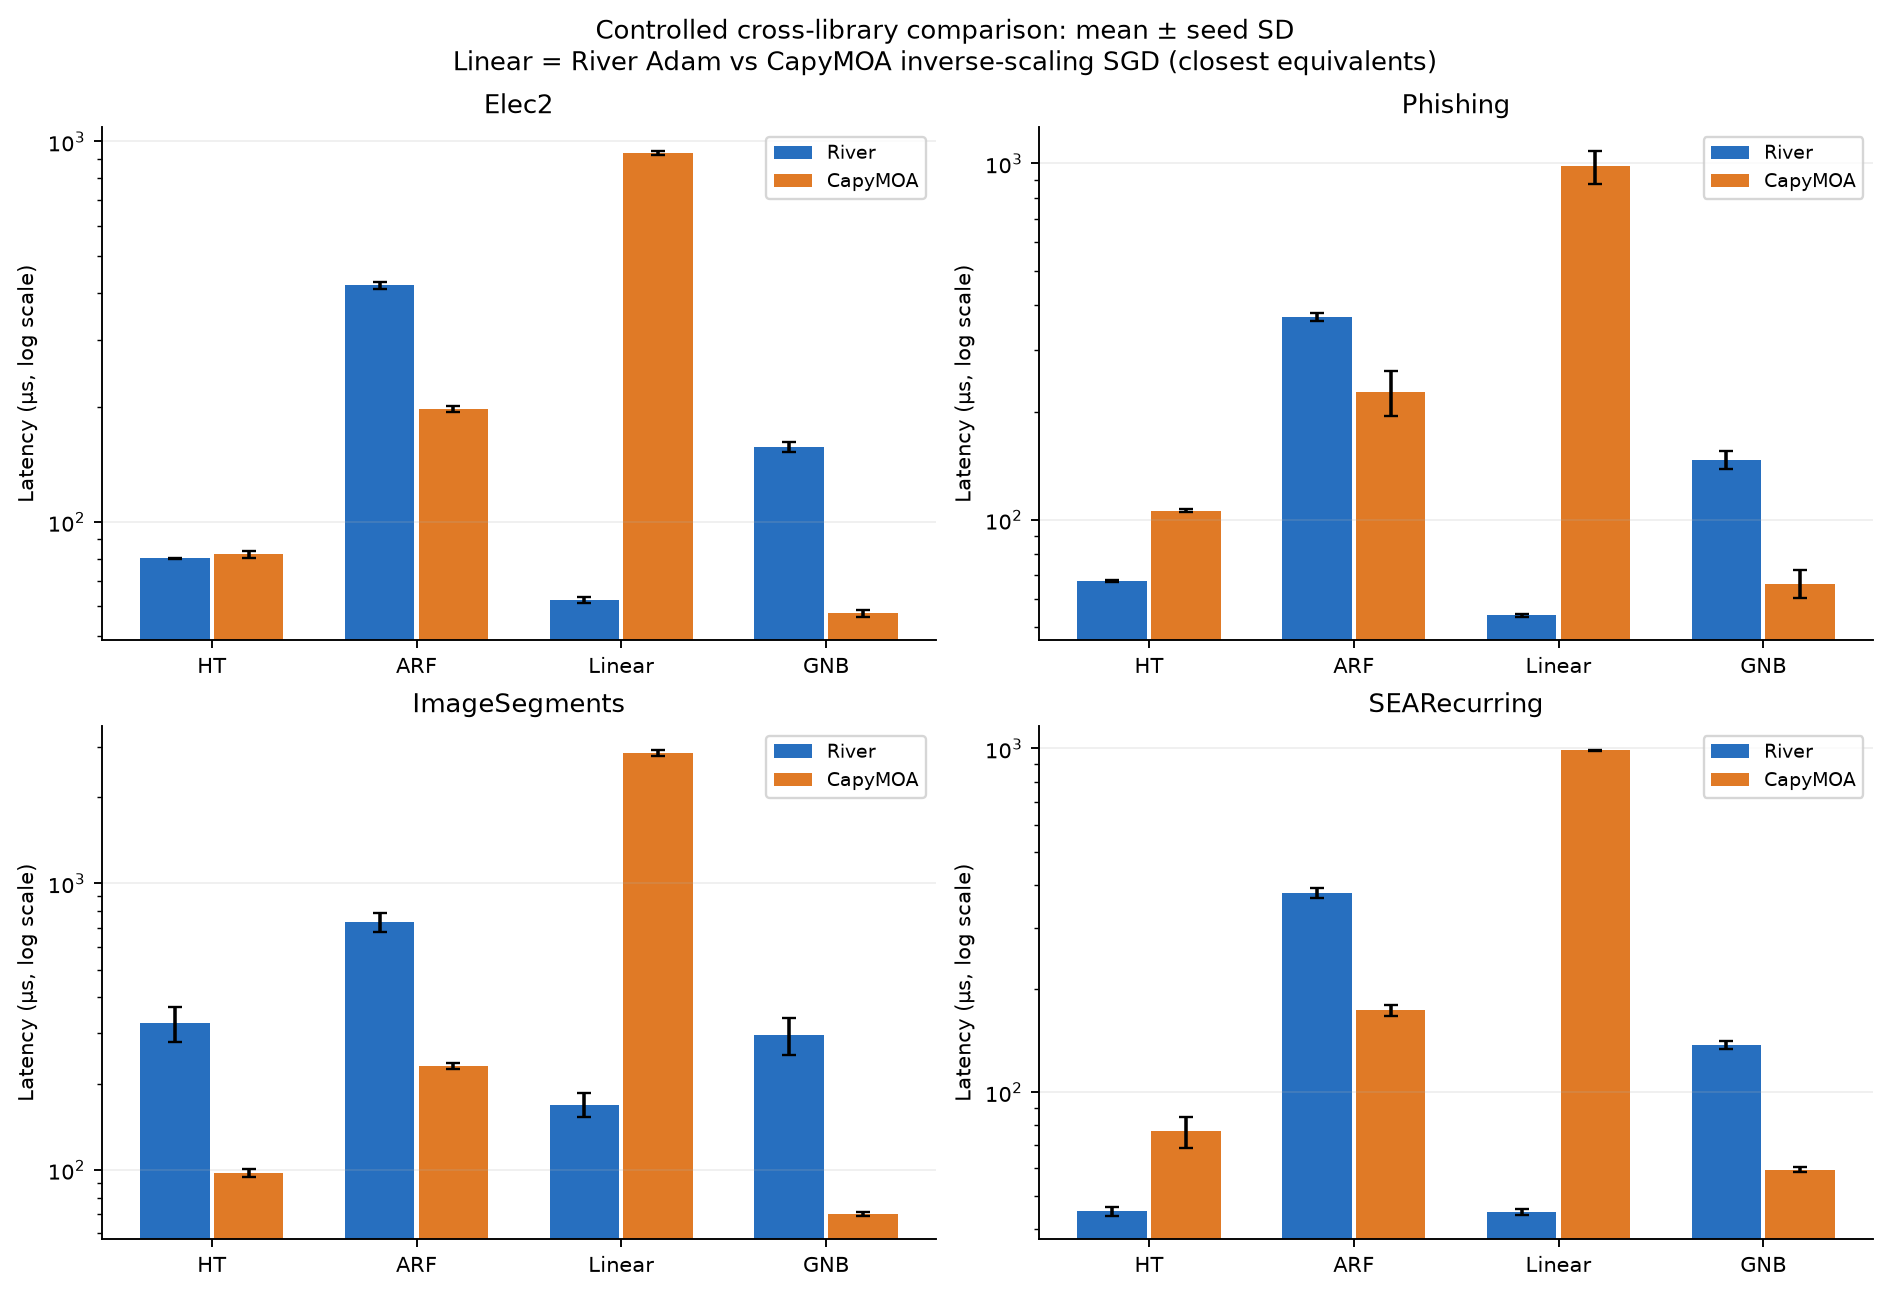

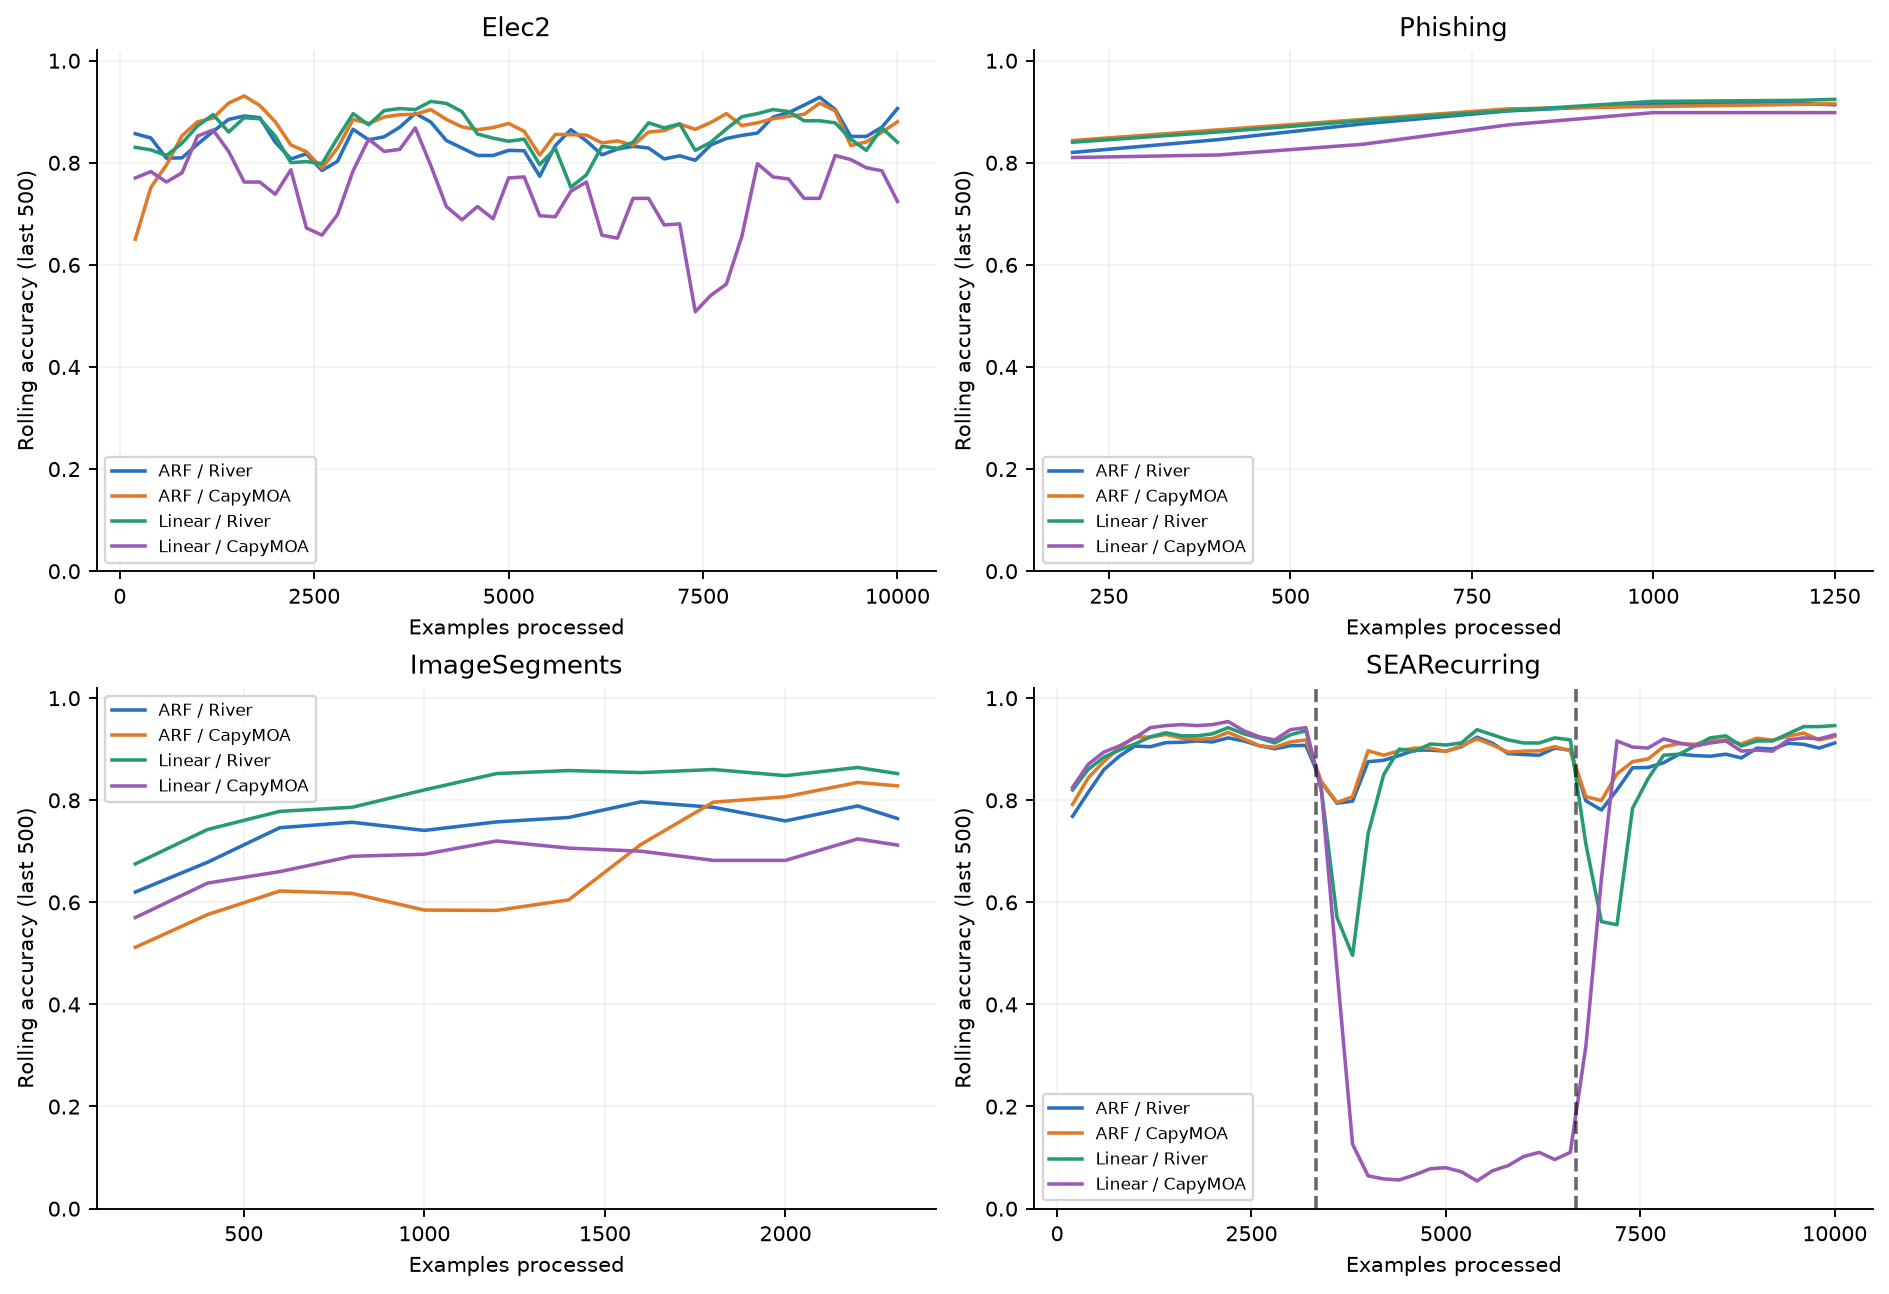

In [3]:
classification=pd.read_csv(OUT/'classification_metrics.csv')
display(classification.groupby(['dataset','model','library'],sort=False)[['accuracy','macro_f1','kappa','mean_latency_us','p95_latency_us','total_runtime_s','sampled_peak_process_rss_mib']].mean().reset_index())
pairs=pd.read_csv(OUT/'classification_pairs.csv')
display(pairs.groupby(['dataset','model'],sort=False)[['accuracy_difference_pp','capy_to_river_latency_ratio']].mean().reset_index())
for name in ['classification_accuracy','classification_latency','classification_curves']:
    display(Image(filename=str(FIG/f'{name}.png')))


### Relationship to Part 1 River results

Data order, sample count and cache hashes are unchanged. Part 2 reruns River with explicit zero-filled features and no tree-depth cap. The following table separates the original profile from this controlled profile, preventing representation/settings changes from being attributed to the library alone.

In [4]:
historical=pd.read_csv(OUT/'part1_historical_comparison.csv')
display(historical.groupby(['dataset','model'],sort=False)[['part1_accuracy','accuracy_river','accuracy_capy','mean_latency_us_river','mean_latency_us_capy']].mean().reset_index())


,dataset,model,part1_accuracy,accuracy_river,accuracy_capy,mean_latency_us_river,mean_latency_us_capy
0,Elec2,HoeffdingTree,0.8545,0.8394,0.8450,80.2897,82.1077
1,Elec2,AdaptiveRandomForest,0.8758,0.8465,0.8640,418.6277,198.3995
2,Elec2,LinearLogistic,0.8508,0.8575,0.7371,62.2236,933.2891
3,Elec2,GaussianNB,0.7940,0.7719,0.7720,157.4374,57.5128
4,Phishing,HoeffdingTree,0.8752,0.8752,0.8816,67.4644,105.8447
5,Phishing,AdaptiveRandomForest,0.8899,0.8899,0.8987,371.2727,228.1436
6,Phishing,LinearLogistic,0.8984,0.8984,0.8672,53.9166,980.5134
7,Phishing,GaussianNB,0.8840,0.8840,0.8840,147.1532,66.1978
8,ImageSegments,HoeffdingTree,0.7779,0.7779,0.7784,325.1881,97.5584
9,ImageSegments,AdaptiveRandomForest,0.7491,0.7491,0.6834,730.6435,230.3001


## Bounded prequential illustration — not part of the formal results

This 100-example prefix uses the supplied data loader and formal model constructor. Each prediction is scored before the current observation is learned. It is a small executable illustration of the API and ordering, not an additional model comparison. No formal result files are written.

In [5]:
# Illustration only: this does not write any formal run, CSV or report.
from capy_lab.common import classification_data, schema_for
from capy_lab.models import classifier as demo_classifier
from capymoa.core import LabeledInstance
from river import metrics as demo_metrics
DEMO_N = 100
demo_x, demo_y, demo_meta = classification_data('Elec2')
demo_schema = schema_for(demo_x.shape[1], len(demo_meta['class_labels']))
demo_model = demo_classifier('CapyMOA', 'HoeffdingTree', demo_schema, demo_x.shape[1], 42, config)
demo_score = demo_metrics.Accuracy()
for demo_row, demo_label in zip(demo_x[:DEMO_N], demo_y[:DEMO_N]):
    demo_prediction = demo_model.predict(LabeledInstance.from_array(demo_schema, demo_row, 0))
    demo_prediction = 0 if demo_prediction is None else int(demo_prediction)
    demo_score.update(int(demo_label), demo_prediction)
    demo_model.train(LabeledInstance.from_array(demo_schema, demo_row, int(demo_label)))
print('ILLUSTRATION ONLY — 100-example prefix; not a formal benchmark result.')
display({'demo_only': True, 'dataset': 'Elec2', 'examples': DEMO_N, 'accuracy': demo_score.get()})


ILLUSTRATION ONLY — 100-example prefix; not a formal benchmark result.


{'demo_only': True, 'dataset': 'Elec2', 'examples': 100, 'accuracy': 0.83}

## Step 9 — Cluster quality and evolution

CluStream, ClusTree and DenStream receive features from ImageSegments, Phishing and a three-component MovingGaussians stream. The first 200 unlabeled points calibrate a subsequently frozen scale. A common weighted KMeans macro stage targets k=3, refreshes every 200 points and uses Hungarian matching to stabilize IDs.

Reference labels are reserved for ARI evaluation; silhouette uses features and assignments. Java instances contain only features plus a constant class-slot zero, avoiding a ClusTree missing-value problem without exposing reference labels.

Each later point is assigned using previous centers before training. Window quality is assessed every 500 points over at most 500 recent assignments. Coverage and undefined silhouette remain explicit. DenStream/Phishing degenerates to one effective cluster under these settings: ARI=0 and silhouette undefined. DenStream uses micro-clusters plus the common macro stage, not native DBSCAN macro output. Snapshots show post-training centers; quality curves preserve historical pre-training assignments.

,dataset,model,mean_window_ari,mean_window_silhouette,mean_window_coverage,mean_window_mse,mean_latency_us,total_runtime_s,final_micro_clusters
0,ImageSegments,CluStream,0.1233,0.2690,1.0000,1.3565,217.0633,0.4800,50.0000
1,ImageSegments,ClusTree,0.1663,0.3234,1.0000,1.2639,108.4035,0.2473,74.0000
2,ImageSegments,DenStream,0.1987,0.2879,1.0000,2.1278,61.7026,0.1479,2.0000
3,Phishing,CluStream,0.2516,0.1694,1.0000,0.6993,143.3476,0.1617,50.0000
4,Phishing,ClusTree,0.2822,0.1653,1.0000,0.7008,121.3712,0.1423,121.0000
5,Phishing,DenStream,0.0000,NaN,1.0000,0.9798,58.5228,0.0668,1.0000
6,MovingGaussians,CluStream,0.9602,0.8229,1.0000,0.0706,124.4789,0.7734,50.0000
7,MovingGaussians,ClusTree,0.9619,0.8243,1.0000,0.0695,91.7862,0.5812,9.0000
8,MovingGaussians,DenStream,0.9397,0.8064,1.0000,0.1517,82.1779,0.5296,62.0000


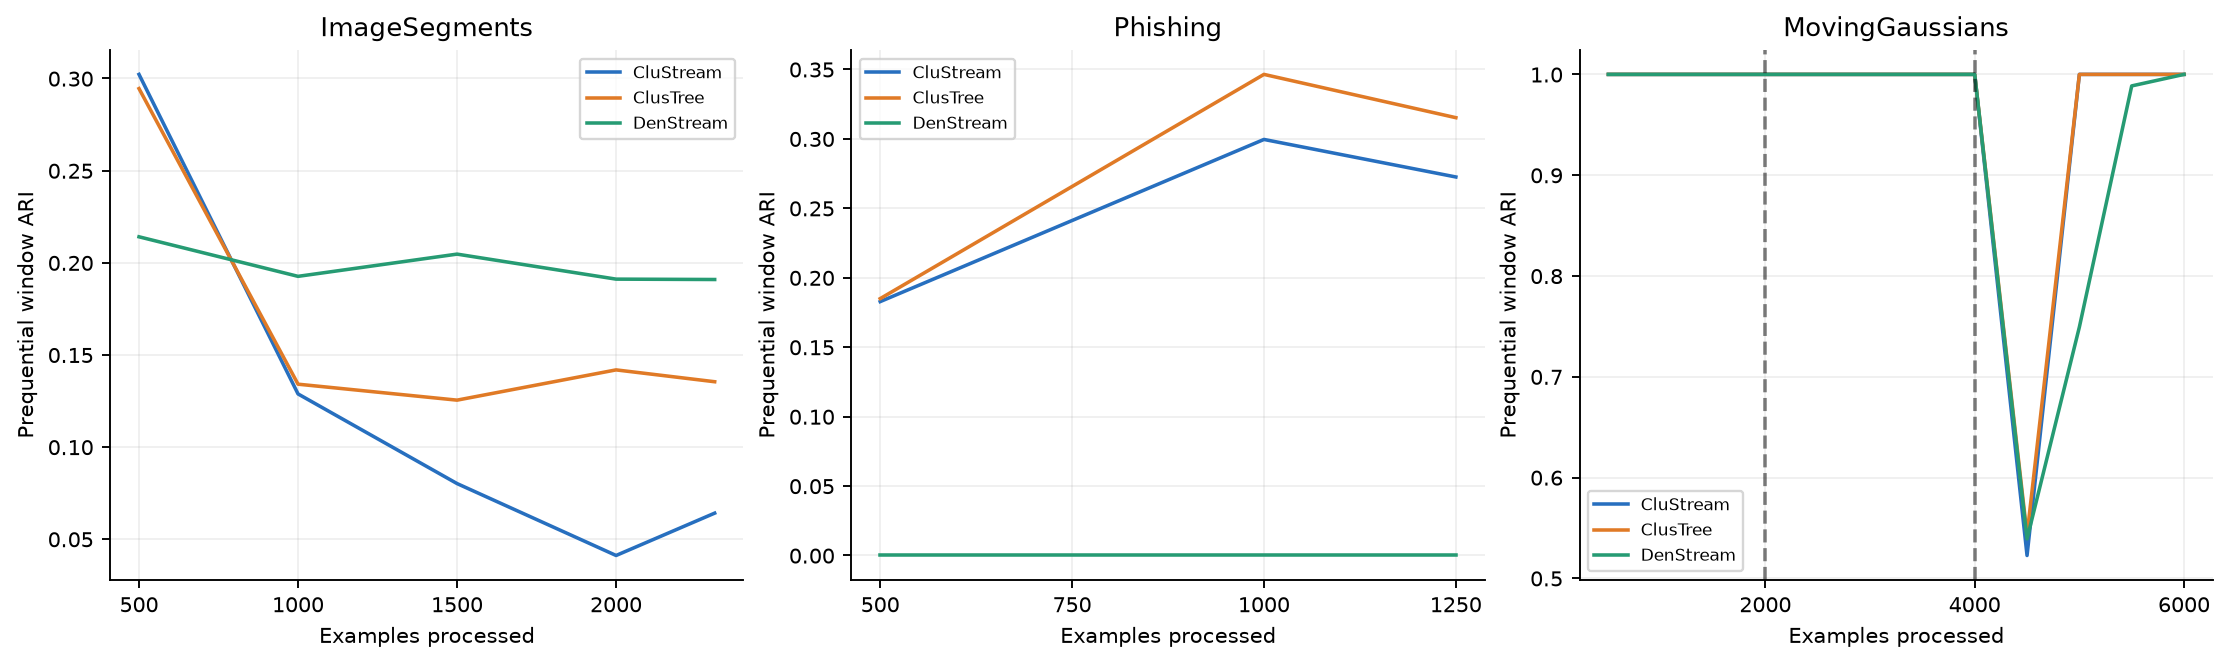

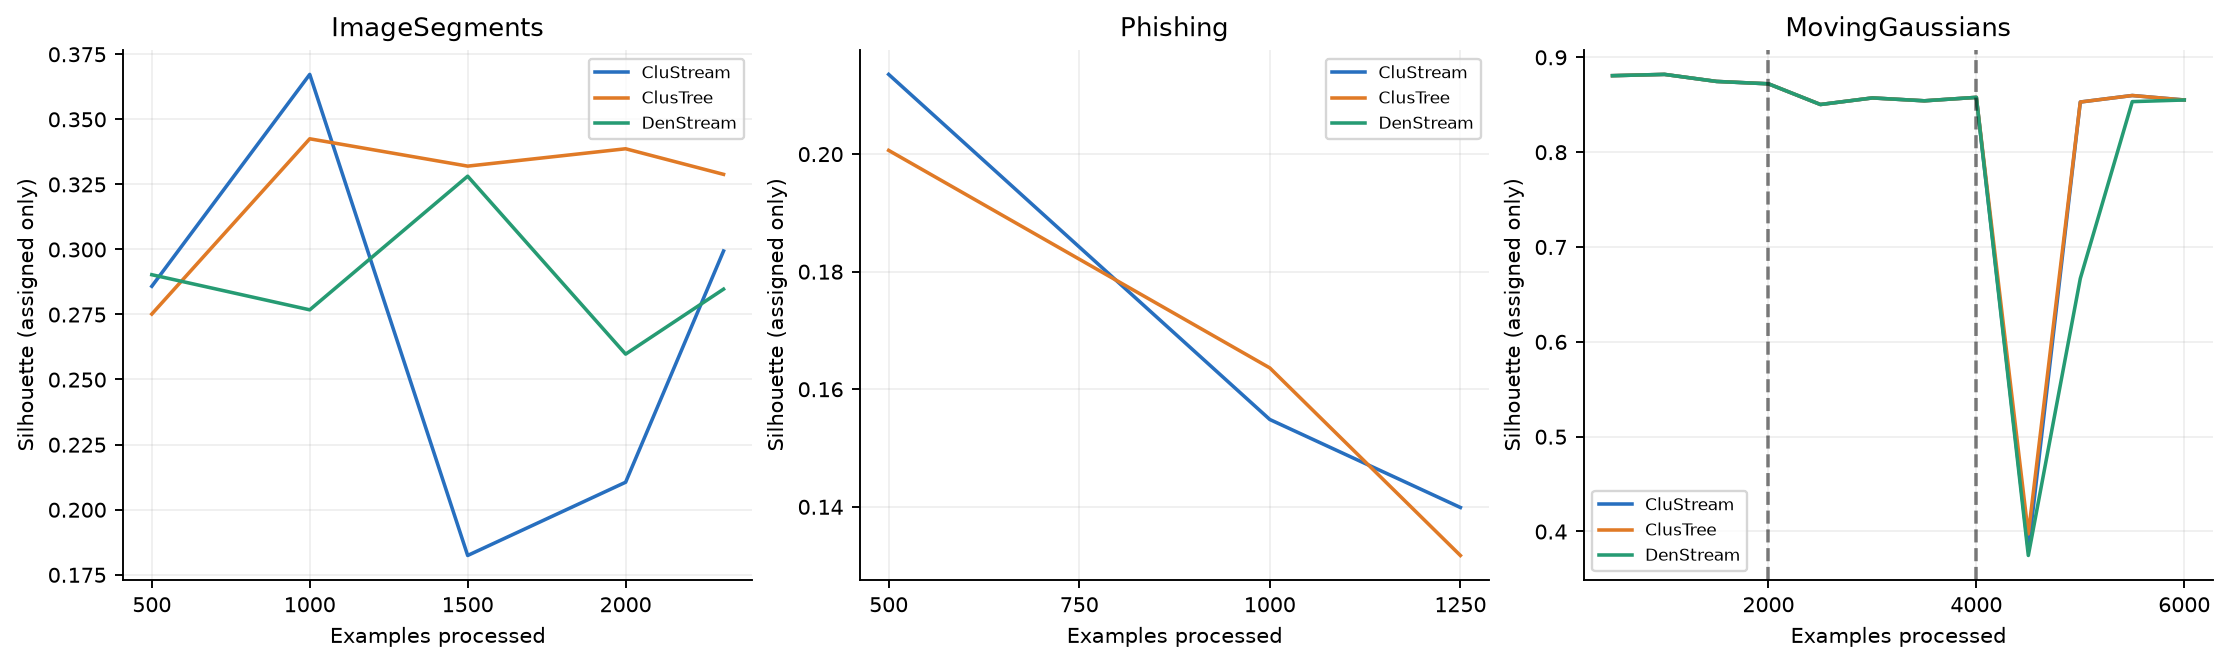

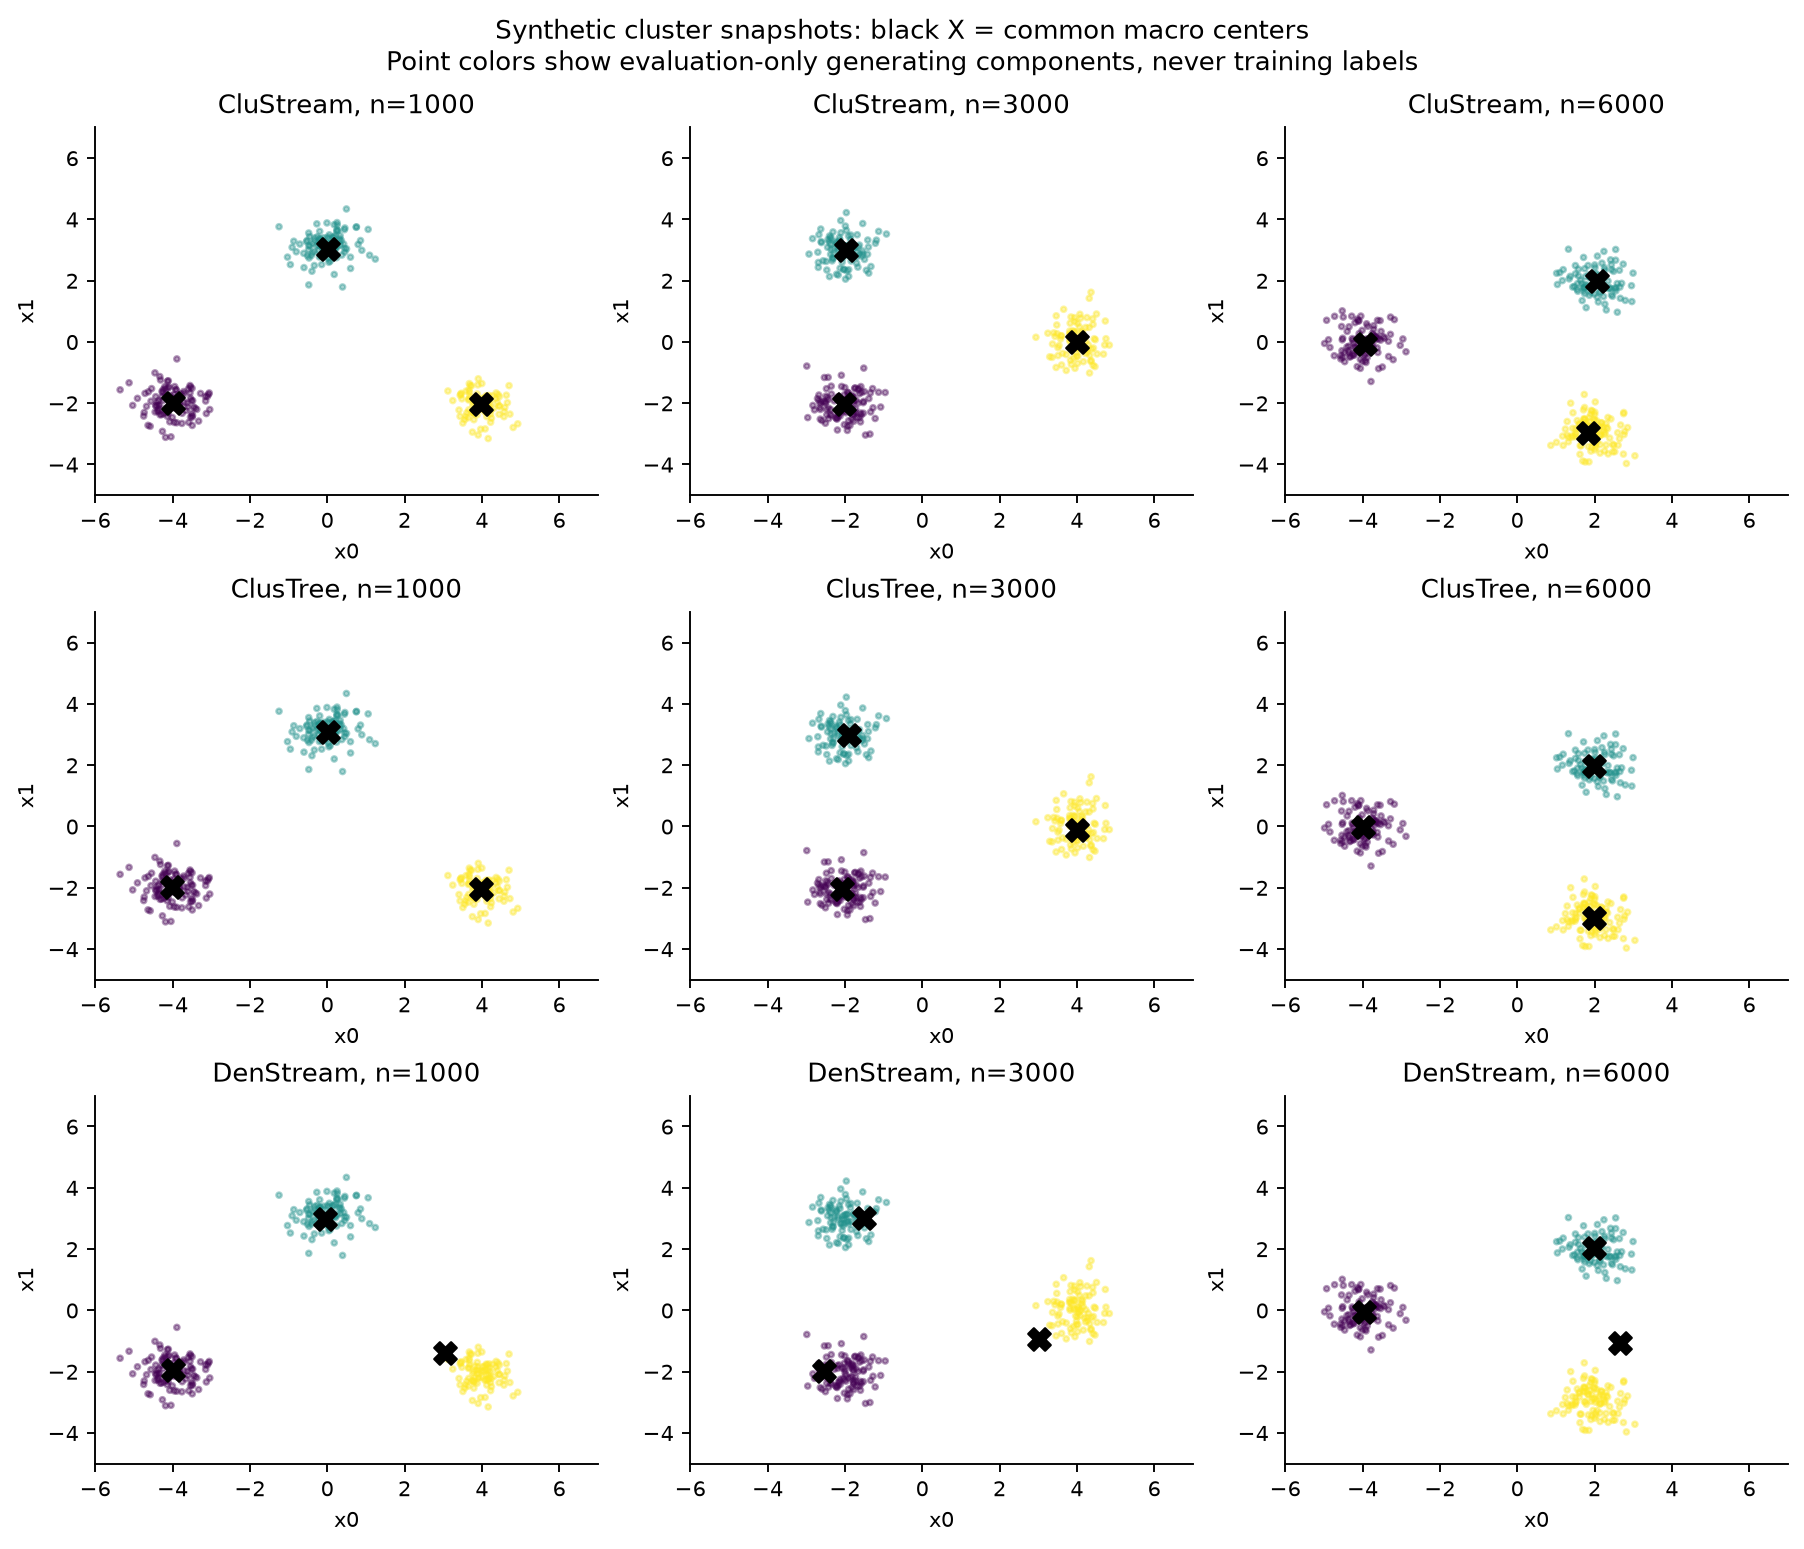

In [6]:
clustering=pd.read_csv(OUT/'clustering_metrics.csv')
display(clustering.groupby(['dataset','model'],sort=False)[['mean_window_ari','mean_window_silhouette','mean_window_coverage','mean_window_mse','mean_latency_us','total_runtime_s','final_micro_clusters']].mean().reset_index())
for name in ['clustering_evolution','clustering_silhouette','clustering_snapshots']:
    display(Image(filename=str(FIG/f'{name}.png')))


## Step 10 — Online AutoML bonus

Compare fixed HT with Bandit, SuccessiveHalving and AutoClass. Bandit and SH share five candidates. Bandit epsilon=0.1, burn-in=100 arm pulls (20 observations with five candidates). SH has nominal budget 2n, which is not a strict total-update cap; actual candidate updates are recorded. Its adapter restricts prediction to active candidates.

AutoClass searches HT/HAT configurations with window 500, ensemble 8 and two new configurations, using the project-local seeded Java overlay. Complete fresh-process reproduction evidence covers predictions and configuration trajectories. Search spaces/budgets differ across selectors, limiting strategy-only comparisons. The outer loop predicts/scores before selector training; no full-stream hindsight oracle is reported.

,dataset,model,accuracy,macro_f1,kappa,mean_latency_us,total_runtime_s
0,Elec2,FixedHT,0.8450,0.8402,0.6810,89.5147,0.9723
1,Elec2,Bandit,0.8793,0.8772,0.7543,4852.4594,49.0649
2,Elec2,SuccessiveHalving,0.8846,0.8826,0.7652,7661.7100,77.2020
3,Elec2,AutoClass,0.8833,0.8810,0.7620,285.2872,2.9814
4,SEARecurring,FixedHT,0.6153,0.6125,0.2252,71.1778,0.8025
5,SEARecurring,Bandit,0.6534,0.6506,0.3029,4981.0691,50.3102
6,SEARecurring,SuccessiveHalving,0.6463,0.6398,0.2805,7211.5912,72.6395
7,SEARecurring,AutoClass,0.8656,0.8643,0.7286,179.4180,1.9098


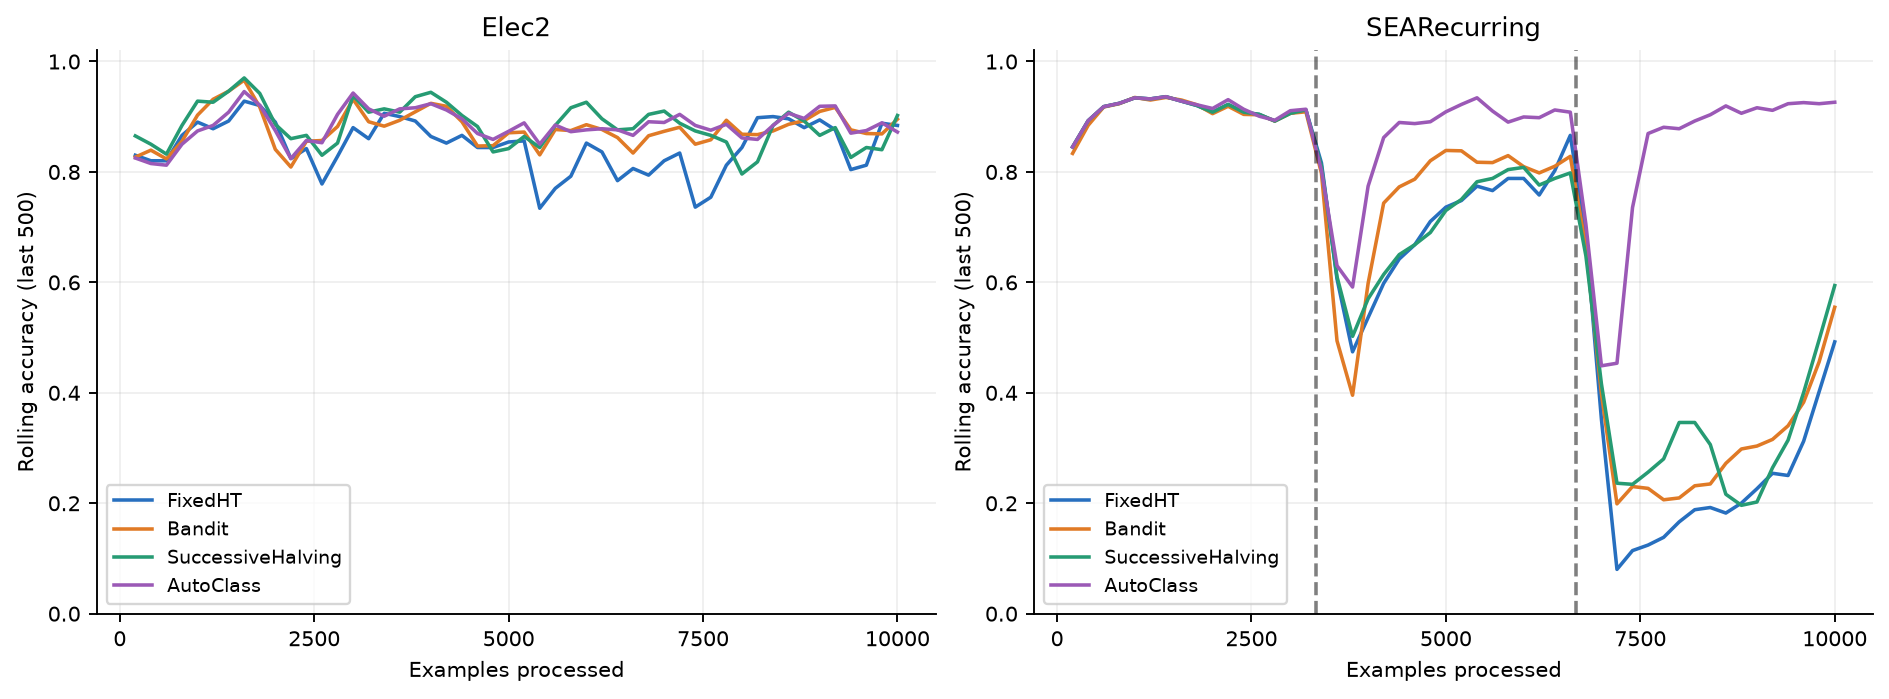

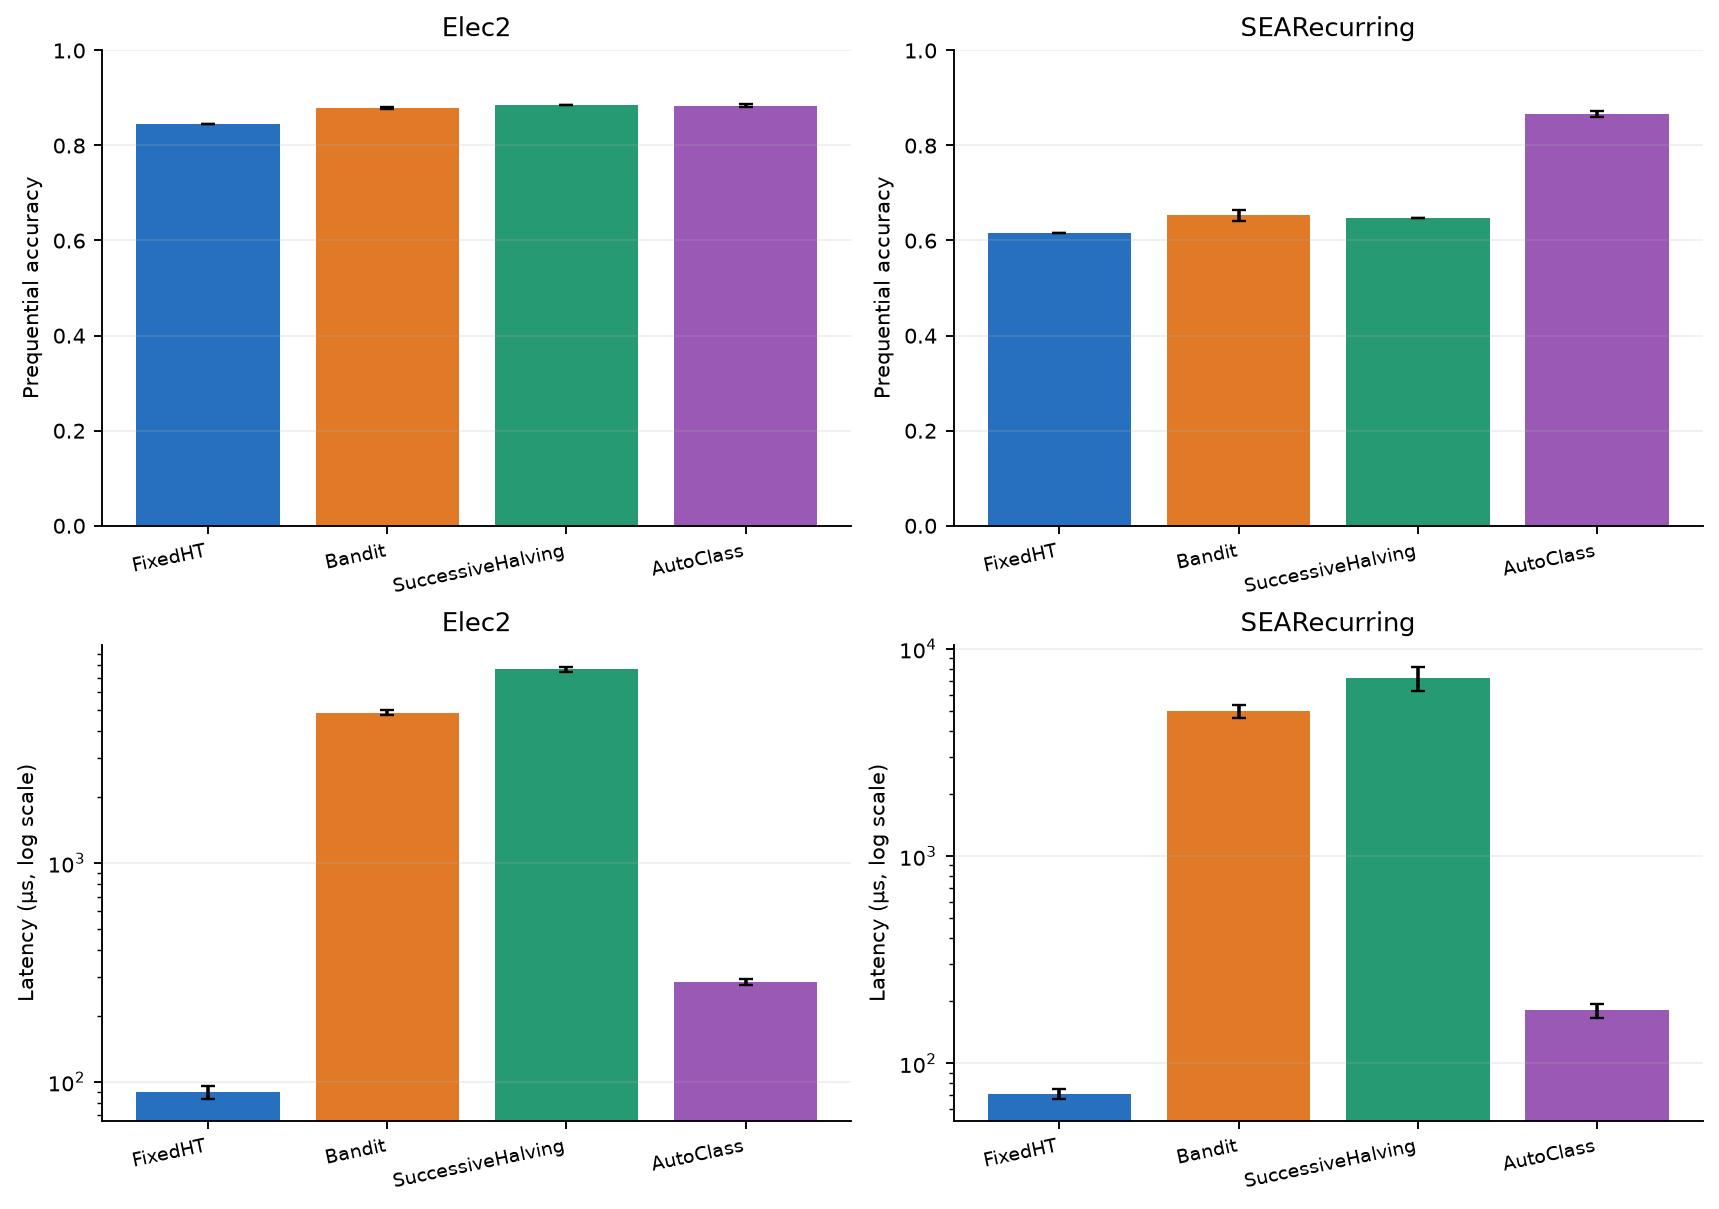

,dataset,model,seed,state,derived_model_updates,budget_counter_scope
0,SEARecurring,AutoClass,43,"{'schema': 2, 'method': 'AutoClass', 'observat...",NaN,NaN
1,Elec2,Bandit,43,"{'schema': 2, 'method': 'Bandit', 'observation...",NaN,NaN
2,Elec2,SuccessiveHalving,43,"{'schema': 2, 'method': 'SuccessiveHalving', '...",23110.0000,Completed rungs only; derived count additional...
3,SEARecurring,SuccessiveHalving,44,"{'schema': 2, 'method': 'SuccessiveHalving', '...",23110.0000,Completed rungs only; derived count additional...
4,SEARecurring,Bandit,44,"{'schema': 2, 'method': 'Bandit', 'observation...",NaN,NaN
5,Elec2,FixedHT,42,"{'method': 'FixedHT', 'observations': 10000}",NaN,NaN
6,Elec2,AutoClass,42,"{'schema': 2, 'method': 'AutoClass', 'observat...",NaN,NaN
7,Elec2,FixedHT,43,"{'method': 'FixedHT', 'observations': 10000}",NaN,NaN
8,Elec2,AutoClass,43,"{'schema': 2, 'method': 'AutoClass', 'observat...",NaN,NaN
9,SEARecurring,Bandit,42,"{'schema': 2, 'method': 'Bandit', 'observation...",NaN,NaN


In [7]:
automl=pd.read_csv(OUT/'automl_metrics.csv')
display(automl.groupby(['dataset','model'],sort=False)[['accuracy','macro_f1','kappa','mean_latency_us','total_runtime_s']].mean().reset_index())
for name in ['automl_curves','automl_accuracy_cost']:
    display(Image(filename=str(FIG/f'{name}.png')))
states=json.loads((OUT/'automl_final_states.json').read_text())
display(pd.DataFrame(states))


## Validation, analysis and source

Raw records, CLI parameters, predictive hashes, selector states, input hashes and timing evidence are in `results/capymoa/`. The entry point is `scripts/run_capy.py`; actual training/evaluation code is in `capy_lab/`. The lab report is submitted separately.

In [8]:
checks=json.loads((OUT/'validation.json').read_text())
assert all(checks.values()),checks
display(pd.DataFrame(checks.items(),columns=['check','passed']))
display(Markdown((OUT/'findings.md').read_text()))


,check,passed
0,classification_coverage,True
1,clustering_coverage,True
2,automl_coverage,True
3,all_147_records_present,True
4,all_calculation_signatures_current_or_verified...,True
5,same_classifier_input_hash_across_libraries,True
6,same_automl_input_hash_per_dataset,True
7,same_clustering_input_hash_per_dataset,True
8,all_classification_metrics_finite,True
9,all_automl_metrics_finite,True


# CapyMOA: measured results and analysis

Steps 7–10 include 96 paired classification runs, 27 stream-clustering runs and 24 AutoML runs. Formal runs are sequential and use a fresh process for each model run. Seeds 42, 43 and 44 share one cached stream per dataset. Dependencies are pinned separately from Part 1.

## Controlled cross-library classification

Both libraries receive identical dense vectors with absent one-hot entries filled by zero. Shared settings include grace=100, memory parameter=64 MiB, NBA leaves, five forest trees, lambda=6, floor(sqrt(d)) features and ADWIN drift/warning deltas 0.002/0.01. Both profiles omit an explicit tree-depth cap because MOA has no matching option.

Linear models share causal scaling, but River Adam(lr=0.01) and CapyMOA inverse-scaling SGD(eta0=0.01, log_loss, no penalty) are different optimizers. Their differences cannot be attributed solely to the library. Backend split statistics, variance handling and random-number implementations also differ. Prediction objects contain a fixed zero class placeholder; true labels enter scoring and subsequent training.

Part 1 uses sparse inputs and tree depth 12. Part 2 reruns River with the aligned profile; the two River result tables must not be treated as an identical configuration.

| dataset | model | library | accuracy | macro_f1 | kappa | mean_latency_us | total_runtime_s |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Elec2 | HoeffdingTree | River | 0.8394 | 0.8344 | 0.6694 | 80.2897 | 0.8623 |
| Elec2 | HoeffdingTree | CapyMOA | 0.8450 | 0.8402 | 0.6810 | 82.1077 | 0.8896 |
| Elec2 | AdaptiveRandomForest | CapyMOA | 0.8640 | 0.8610 | 0.7221 | 198.3995 | 2.0658 |
| Elec2 | AdaptiveRandomForest | River | 0.8465 | 0.8421 | 0.6847 | 418.6277 | 4.2634 |
| Elec2 | LinearLogistic | River | 0.8575 | 0.8542 | 0.7085 | 62.2236 | 0.6815 |
| Elec2 | LinearLogistic | CapyMOA | 0.7371 | 0.7009 | 0.4315 | 933.2891 | 9.4238 |
| Elec2 | GaussianNB | CapyMOA | 0.7720 | 0.7588 | 0.5227 | 57.5128 | 0.6366 |
| Elec2 | GaussianNB | River | 0.7719 | 0.7588 | 0.5226 | 157.4374 | 1.6449 |
| Phishing | HoeffdingTree | River | 0.8752 | 0.8734 | 0.7468 | 67.4644 | 0.0915 |
| Phishing | HoeffdingTree | CapyMOA | 0.8816 | 0.8803 | 0.7608 | 105.8447 | 0.1409 |
| Phishing | AdaptiveRandomForest | CapyMOA | 0.8987 | 0.8970 | 0.7940 | 228.1436 | 0.2953 |
| Phishing | AdaptiveRandomForest | River | 0.8899 | 0.8880 | 0.7759 | 371.2727 | 0.4735 |
| Phishing | LinearLogistic | River | 0.8984 | 0.8973 | 0.7948 | 53.9166 | 0.0748 |
| Phishing | LinearLogistic | CapyMOA | 0.8672 | 0.8662 | 0.7327 | 980.5134 | 1.2374 |
| Phishing | GaussianNB | CapyMOA | 0.8840 | 0.8826 | 0.7652 | 66.1978 | 0.0912 |
| Phishing | GaussianNB | River | 0.8840 | 0.8828 | 0.7656 | 147.1532 | 0.1926 |
| ImageSegments | HoeffdingTree | River | 0.7779 | 0.7664 | 0.7409 | 325.1881 | 0.7696 |
| ImageSegments | HoeffdingTree | CapyMOA | 0.7784 | 0.7680 | 0.7414 | 97.5584 | 0.2417 |
| ImageSegments | AdaptiveRandomForest | CapyMOA | 0.6834 | 0.6734 | 0.6306 | 230.3001 | 0.5514 |
| ImageSegments | AdaptiveRandomForest | River | 0.7491 | 0.7465 | 0.7072 | 730.6435 | 1.7070 |
| ImageSegments | LinearLogistic | River | 0.8203 | 0.8039 | 0.7904 | 168.9017 | 0.4068 |
| ImageSegments | LinearLogistic | CapyMOA | 0.6840 | 0.6453 | 0.6313 | 2855.2403 | 6.6189 |
| ImageSegments | GaussianNB | CapyMOA | 0.7788 | 0.7686 | 0.7419 | 70.1726 | 0.1782 |
| ImageSegments | GaussianNB | River | 0.7333 | 0.7318 | 0.6889 | 295.0696 | 0.7015 |
| SEARecurring | HoeffdingTree | River | 0.6146 | 0.6119 | 0.2240 | 44.9213 | 0.5086 |
| SEARecurring | HoeffdingTree | CapyMOA | 0.6153 | 0.6125 | 0.2252 | 76.7925 | 0.8560 |
| SEARecurring | AdaptiveRandomForest | CapyMOA | 0.8957 | 0.8946 | 0.7892 | 173.0693 | 1.8203 |
| SEARecurring | AdaptiveRandomForest | River | 0.8836 | 0.8823 | 0.7646 | 380.1403 | 3.8852 |
| SEARecurring | LinearLogistic | River | 0.8722 | 0.8711 | 0.7422 | 44.8906 | 0.5088 |
| SEARecurring | LinearLogistic | CapyMOA | 0.6393 | 0.6253 | 0.2575 | 988.3997 | 9.9796 |
| SEARecurring | GaussianNB | CapyMOA | 0.6344 | 0.6217 | 0.2489 | 59.4713 | 0.6611 |
| SEARecurring | GaussianNB | River | 0.6343 | 0.6216 | 0.2488 | 137.1619 | 1.4457 |

Accuracy differences below are CapyMOA minus River in percentage points. A latency ratio below one favors CapyMOA under these interfaces and settings, not necessarily its isolated kernel.

| dataset | model | accuracy_difference_pp | capy_to_river_latency_ratio |
| --- | --- | --- | --- |
| Elec2 | HoeffdingTree | 0.5600 | 1.0227 |
| Elec2 | AdaptiveRandomForest | 1.7467 | 0.4742 |
| Elec2 | LinearLogistic | -12.0400 | 15.0026 |
| Elec2 | GaussianNB | 0.0100 | 0.3657 |
| Phishing | HoeffdingTree | 0.6400 | 1.5690 |
| Phishing | AdaptiveRandomForest | 0.8800 | 0.6138 |
| Phishing | LinearLogistic | -3.1200 | 18.1929 |
| Phishing | GaussianNB | 0.0000 | 0.4493 |
| ImageSegments | HoeffdingTree | 0.0433 | 0.3030 |
| ImageSegments | AdaptiveRandomForest | -6.5657 | 0.3169 |
| ImageSegments | LinearLogistic | -13.6364 | 17.0017 |
| ImageSegments | GaussianNB | 4.5455 | 0.2406 |
| SEARecurring | HoeffdingTree | 0.0700 | 1.7127 |
| SEARecurring | AdaptiveRandomForest | 1.2067 | 0.4553 |
| SEARecurring | LinearLogistic | -23.2900 | 22.0231 |
| SEARecurring | GaussianNB | 0.0100 | 0.4338 |

- Elec2: highest controlled mean accuracy: CapyMOA / AdaptiveRandomForest, 86.40%.
- Phishing: highest controlled mean accuracy: CapyMOA / AdaptiveRandomForest, 89.87%.
- ImageSegments: highest controlled mean accuracy: River / LinearLogistic, 82.03%.
- SEARecurring: highest controlled mean accuracy: CapyMOA / AdaptiveRandomForest, 89.57%.

## Unsupervised stream clustering

CluStream, ClusTree and DenStream receive features from ImageSegments, Phishing and the 6,000-point MovingGaussians stream (changes at 2000/4000). Reference labels/components are reserved for ARI and never used to train or tune the learners. A fixed class-slot zero avoids a ClusTree missing-value problem.

CluStream uses horizon 1000 and 50 kernels; ClusTree uses horizon 1000, height 5 and depth-first insertion. DenStream uses horizon 1000, epsilon 0.5, beta 0.2, mu 10, init 100, lambda 0.25 and speed 100. A common weighted KMeans macro stage targets k=3 and refreshes every 200 observations; Hungarian matching stabilizes IDs. DenStream native DBSCAN macro/noise output is not evaluated.

The first 200 unlabeled points calibrate and initialize the learners. Scaling then freezes and distances are normalized by sqrt(d). Subsequent points are assigned using previous centers before training. Window scores are recorded every 500 points; silhouette samples at most 200 assigned points. Coverage is explicit and invalid silhouette remains missing.

| dataset | model | mean_window_ari | mean_window_silhouette | mean_window_coverage | mean_latency_us |
| --- | --- | --- | --- | --- | --- |
| ImageSegments | CluStream | 0.1233 | 0.2690 | 1.0000 | 217.0633 |
| ImageSegments | ClusTree | 0.1663 | 0.3234 | 1.0000 | 108.4035 |
| ImageSegments | DenStream | 0.1987 | 0.2879 | 1.0000 | 61.7026 |
| Phishing | CluStream | 0.2516 | 0.1694 | 1.0000 | 143.3476 |
| Phishing | ClusTree | 0.2822 | 0.1653 | 1.0000 | 121.3712 |
| Phishing | DenStream | 0.0000 | — | 1.0000 | 58.5228 |
| MovingGaussians | CluStream | 0.9602 | 0.8229 | 1.0000 | 124.4789 |
| MovingGaussians | ClusTree | 0.9619 | 0.8243 | 1.0000 | 91.7862 |
| MovingGaussians | DenStream | 0.9397 | 0.8064 | 1.0000 | 82.1779 |

Synthetic components are recovered well, with a temporary ARI reduction in relocation-spanning windows. Fixed k=3 cannot exactly represent the seven ImageSegments labels. DenStream/Phishing degenerates to one effective cluster: ARI=0 and silhouette undefined. Low latency in that setting is not evidence of useful clustering. Snapshots show centers after training to that position; quality curves use historical pre-training assignments.

## Online AutoML

FixedHT is compared with epsilon-greedy Bandit, SuccessiveHalving and AutoClass on identical Elec2/SEA streams. Outer prediction/scoring precedes selector training; no full-stream hindsight oracle is used. Bandit and SH share five HT/HAT candidates. Bandit epsilon=0.1 and burn-in=100 arm pulls (20 all-arm observations). SH eta=2 has nominal budget 2n; its completed-rung counter is not a strict total-update cap, and actual updates are recorded. SH predictions remain in the active set.

AutoClass searches HT/HAT configurations with window 500, ensemble 8 and two new configurations on one core. The seeded Java overlay uses per-learner randomness; six formal prediction/configuration trajectories have matching fresh-process reproduction evidence. AutoML spaces and budgets differ, limiting pure strategy comparisons.

| dataset | model | accuracy | macro_f1 | mean_latency_us | total_runtime_s |
| --- | --- | --- | --- | --- | --- |
| Elec2 | FixedHT | 0.8450 | 0.8402 | 89.5147 | 0.9723 |
| Elec2 | Bandit | 0.8793 | 0.8772 | 4852.4594 | 49.0649 |
| Elec2 | SuccessiveHalving | 0.8846 | 0.8826 | 7661.7100 | 77.2020 |
| Elec2 | AutoClass | 0.8833 | 0.8810 | 285.2872 | 2.9814 |
| SEARecurring | FixedHT | 0.6153 | 0.6125 | 71.1778 | 0.8025 |
| SEARecurring | Bandit | 0.6534 | 0.6506 | 4981.0691 | 50.3102 |
| SEARecurring | SuccessiveHalving | 0.6463 | 0.6398 | 7211.5912 | 72.6395 |
| SEARecurring | AutoClass | 0.8656 | 0.8643 | 179.4180 | 1.9098 |

- Elec2: highest AutoML-study accuracy: SuccessiveHalving (88.46%); lowest latency: FixedHT (89.5 µs). The separate fixed ARF reference reaches 86.40% at 198.4 µs. Beating ordinary HT does not imply beating every strong fixed learner.
- SEARecurring: highest AutoML-study accuracy: AutoClass (86.56%); lowest latency: FixedHT (71.2 µs). The separate fixed ARF reference reaches 89.57% at 173.1 µs. Beating ordinary HT does not imply beating every strong fixed learner.

## Cost, validation and limits

The JVM heap limit is 4 GiB, ActiveProcessorCount=1, forest jobs=1 and BLAS threads=1. Initial construction, imports and cache loading are excluded from item latency. First-call/JIT costs remain. Classification latency includes conversion and preprocessing; clustering includes macro refresh but excludes fixed-array calibration/scaling. Evaluation enters total time. RSS includes the process/JVM and is sampled rather than model-exclusive.

Data hashes, per-run parameters, predictive hashes, selector states, logs and raw records are supplied in results/capymoa/. Classifier comparisons retain optimizer/backend differences. Real static order is not validated drift truth. Common k/scale, unequal search budgets, shared stream realizations and Java kernels without exposed seeds constrain interpretation. The executed notebooks and CSV exports provide the analysis outputs.


## Reproduction commands

Use a separate working copy when training, because the runner replaces result files. Only the explicitly labeled 100-example illustration fits a learner in the default mode; formal results are read from saved evidence.

```bash
source .venv-capy/bin/activate
python scripts/run_capy.py all --resume
python scripts/run_capy.py analyze
python -m unittest discover -s tests -v
python scripts/build_capy_notebook.py
python -m jupyter nbconvert --execute --to notebook --inplace notebooks/capymoa_steps_7_10.ipynb --ExecutePreprocessor.kernel_name=lab4-capy
```

References: [installation](https://capymoa.org/setup/), [classification](https://capymoa.org/notebooks/classifier/getting_started.html), [clustering](https://capymoa.org/notebooks/clusterer/clustering.html), [AutoML](https://capymoa.org/notebooks/automl/automl.html).